# Casus A: Dynamic Modelling (ODEs)

In this notebook we shall explore the concept of dynamic modelling. We have used a collection of different models: Bertalanffy, Exponential, Logistic and Gompertz. With these defined models, we have looked at tumor growth data. To do this, we have applied the ODE solvers scipy and Euler. Next, we applied optimization methods. For this we looked at the methods Hooke & Jeeves and Monte Carlo. Lastly, the data is compared using BIC and AICc.

The used dataset is a simulated dataset which contains different tumors and different treatments. Link: https://github.com/DennisDean/TumorVolumetrics/blob/master/data/synthetic_tumor_data.csv

With this dataset we wanted to explore the growth of different tumors, with a collection of different models. We wanted to find out what the most accurate model, ODE and optimization method is for this dataset.

Research question: Which tumor growth model best describes the observed tumor development?

***

## Data Loading

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import modules from your package
from solvers.euler import euler_solver
from solvers.ODE_scipy import solve_ode

We observe the format of the data file by displaying the first lines.

In [36]:
! head /Users/cheyennebrouwer/Documents/26-27/Kwartaal_2/synthetic_tumor_data.csv

Contributor,Arms,Times,Volume,Experiment,Study,ID,Tumor,Disease_Type,Body_Weight,Matched_Controls
Synthetic_Set_1,Treatment_A,0,215.342,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.23,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,4,298.567,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.01,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,8,356.421,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.78,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,12,389.234,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.92,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,15,421.567,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.11,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,18,498.342,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.03,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,21,567.891,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.87,Treatment_A_Control_1
Synthetic_Set_1,Treatment_A,25,712.456,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.93,Treatment_A_Control_1
Synthetic

The data exists of 8 attributes, which have different units. The data is comma separated and contains a header with column names. We define a codebook on basis of the original publication.

In [37]:
codebook = {
    "attribute": [
        "Contributor",
        "Arms",
        "Times",
        "Volume",
        "Experiment",
        "Study",
        "ID",
        "Tumor",
        "Disease_Type",
        "Body_Weight",
        "Matched_Controls"
    ],
    "unit": [
        "-",
        "-",
        "days",
        "mm³",
        "-",
        "-",
        "-",
        "-",
        "-",
        "grams",
        "-"
    ],
    "dtype": [
        "object",
        "object",
        "int64",
        "float64",
        "object",
        "object",
        "object",
        "object",
        "object",
        "float64",
        "object"
    ],
    "description": [
        "Name or identifier of the dataset contributor. Groups related samples or experiments.",
        "Experimental treatment group or control group assigned to the subject.",
        "Time point at which the tumor volume was measured, in days.",
        "Measured tumor volume at the corresponding time point, measured in mm³",
        "Experiment identifier for tracking multiple experiments.",
        "Identifier of the study to which the experiment belongs.",
        "Unique identifier for each tumor sample or PDX (patient-derived xenograft) model.",
        "Name or identifier of the tumor model.",
        "Description or classification of the tumor type.",
        "Body weight of the subject at the corresponding measurement, in grams",
        "Identifier linking the experimental group to its matched control group."
    ]
}
pd.DataFrame(codebook).set_index("attribute")

,unit,dtype,description
attribute,,,
Contributor,-,object,Name or identifier of the dataset contributor....
Arms,-,object,Experimental treatment group or control group ...
Times,days,int64,Time point at which the tumor volume was measu...
Volume,mm³,float64,Measured tumor volume at the corresponding tim...
Experiment,-,object,Experiment identifier for tracking multiple ex...
Study,-,object,Identifier of the study to which the experimen...
ID,-,object,Unique identifier for each tumor sample or PDX...
Tumor,-,object,Name or identifier of the tumor model.
Disease_Type,-,object,Description or classification of the tumor type.


We load the data as follows.

In [38]:
codebook["label"] = [f"{attribute} [{unit}]" for attribute, unit in zip(codebook["attribute"], codebook["unit"])]

data = pd.read_csv("../synthetic_tumor_data.csv", names=codebook["label"], header=0)

data.head()

,Contributor [-],Arms [-],Times [days],Volume [mm³],Experiment [-],Study [-],ID [-],Tumor [-],Disease_Type [-],Body_Weight [grams],Matched_Controls [-]
0,Synthetic_Set_1,Treatment_A,0,215.342,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.23,Treatment_A_Control_1
1,Synthetic_Set_1,Treatment_A,4,298.567,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.01,Treatment_A_Control_1
2,Synthetic_Set_1,Treatment_A,8,356.421,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.78,Treatment_A_Control_1
3,Synthetic_Set_1,Treatment_A,12,389.234,EXP,EXP_1,Model1_101,Model1,Synthetic Models,14.92,Treatment_A_Control_1
4,Synthetic_Set_1,Treatment_A,15,421.567,EXP,EXP_1,Model1_101,Model1,Synthetic Models,15.11,Treatment_A_Control_1


We verify that all 185 rows and 11 columns have been loaded.

In [39]:
data.shape

(185, 11)

We have made overview of the dataset.

In [40]:
data.describe(include="all")

,Contributor [-],Arms [-],Times [days],Volume [mm³],Experiment [-],Study [-],ID [-],Tumor [-],Disease_Type [-],Body_Weight [grams],Matched_Controls [-]
count,185,185,185.000000,185.000000,185,185,185,185,185,185.000000,185
unique,1,4,NaN,NaN,1,4,25,4,1,NaN,15
top,Synthetic_Set_1,Control,NaN,NaN,EXP,EXP_1,Model1_101,Model1,Synthetic Models,NaN,Treatment_A_Control_1
freq,185,89,NaN,NaN,185,72,8,72,185,NaN,16
mean,NaN,NaN,11.464865,810.812832,NaN,NaN,NaN,NaN,NaN,15.633622,NaN
std,NaN,NaN,7.617208,722.463116,NaN,NaN,NaN,NaN,NaN,1.108299,NaN
min,NaN,NaN,0.000000,17.591000,NaN,NaN,NaN,NaN,NaN,13.340000,NaN
25%,NaN,NaN,4.000000,340.234000,NaN,NaN,NaN,NaN,NaN,14.870000,NaN
50%,NaN,NaN,12.000000,567.891000,NaN,NaN,NaN,NaN,NaN,15.470000,NaN
75%,NaN,NaN,18.000000,1092.234000,NaN,NaN,NaN,NaN,NaN,16.450000,NaN


We verify there are no missing values.

In [41]:
data.isnull().sum()

Contributor [-]         0
Arms [-]                0
Times [days]            0
Volume [mm³]            0
Experiment [-]          0
Study [-]               0
ID [-]                  0
Tumor [-]               0
Disease_Type [-]        0
Body_Weight [grams]     0
Matched_Controls [-]    0
dtype: int64

#### Conclusion

The data has been loaded correctly and is suitable to be used in further processing.

***

## Data Visualisation

To explore the correlation between attributes, we deploy scatterplots and calculate correlations.

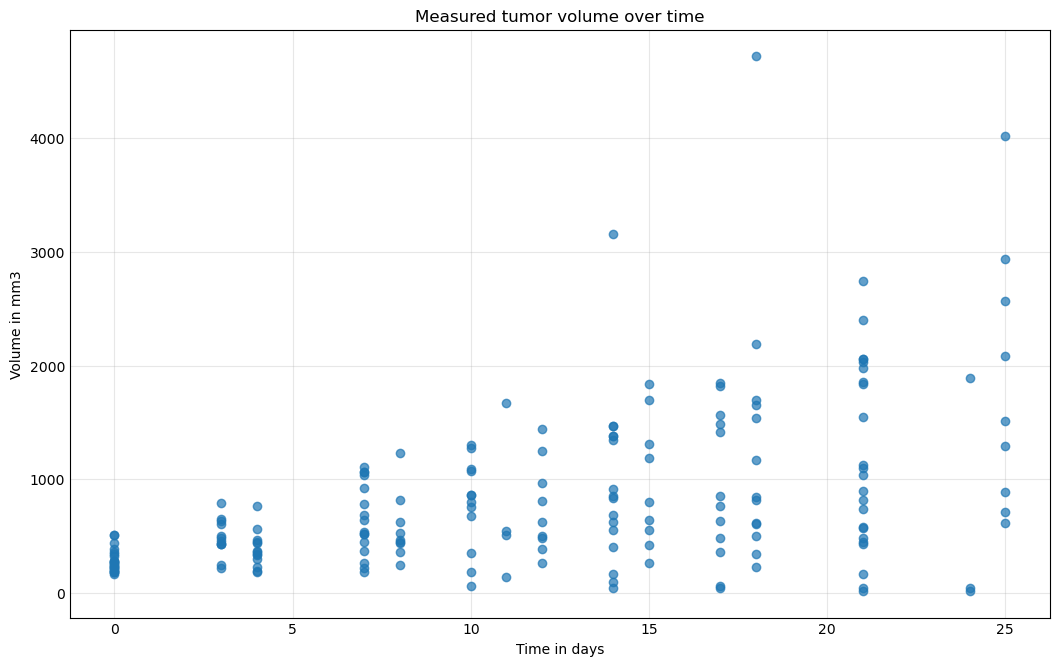

In [44]:
plt.figure(figsize=(10,6))

plt.scatter(
    data["Times [days]"],
    data["Volume [mm³]"],
    alpha=0.7
)

plt.xlabel("Time in days")
plt.ylabel("Volume in mm3")
plt.title("Measured tumor volume over time")

plt.grid(alpha=0.3)
plt.show()

In the violinplot below, we show the distribution of tumor volume per treatment. This is the beginning volume, before any predictions have been done.

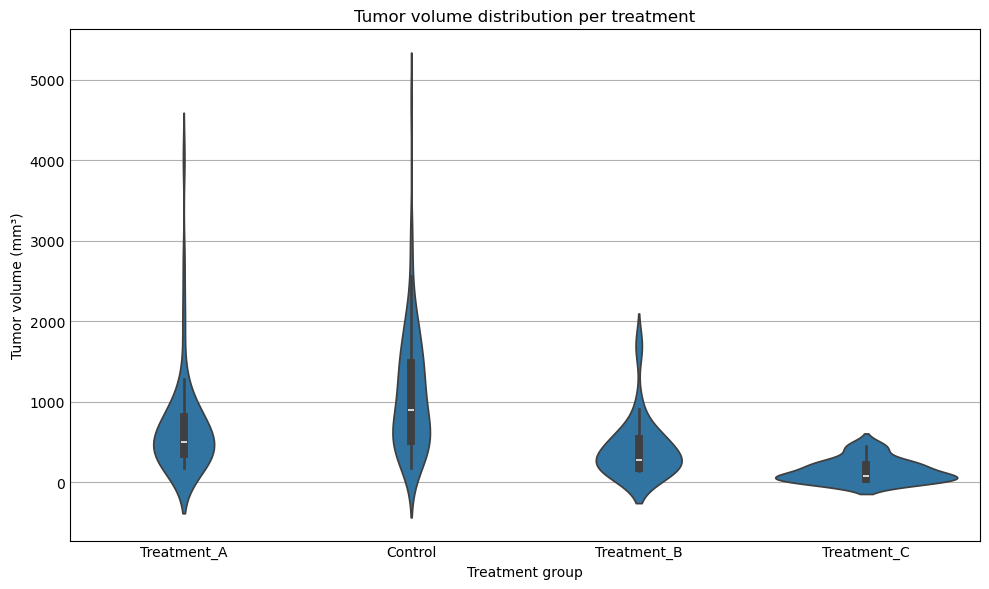

In [49]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=data,
    x="Arms [-]",
    y="Volume [mm³]",
    inner="box"
)

plt.xlabel("Treatment group")
plt.ylabel("Tumor volume (mm³)")
plt.title("Tumor volume distribution per treatment")

plt.tight_layout()
plt.show()

The boxplot below shows the distribution of tumor volumes.

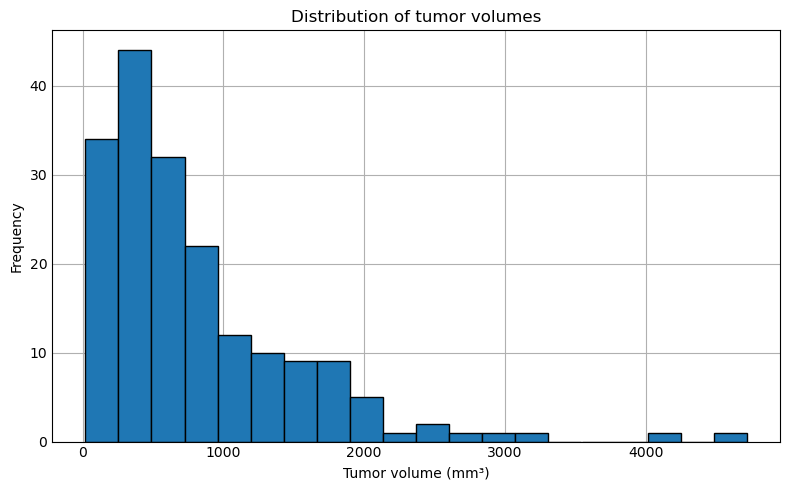

In [50]:
plt.figure(figsize=(8, 5))

plt.hist(data["Volume [mm³]"], bins=20, edgecolor="black")

plt.xlabel("Tumor volume (mm³)")
plt.ylabel("Frequency")
plt.title("Distribution of tumor volumes")

plt.tight_layout()
plt.show()

Conclusion: The frequency of tumor volume per mm3 is the highest below 1000mm3.

The boxplot below shows the distribution and outliers of tumor volumes. This is useful because it provides insight into the variation in tumor sizes, helps identify unusually large or small tumor volumes, and allows us to assess the spread and median of the measurements.

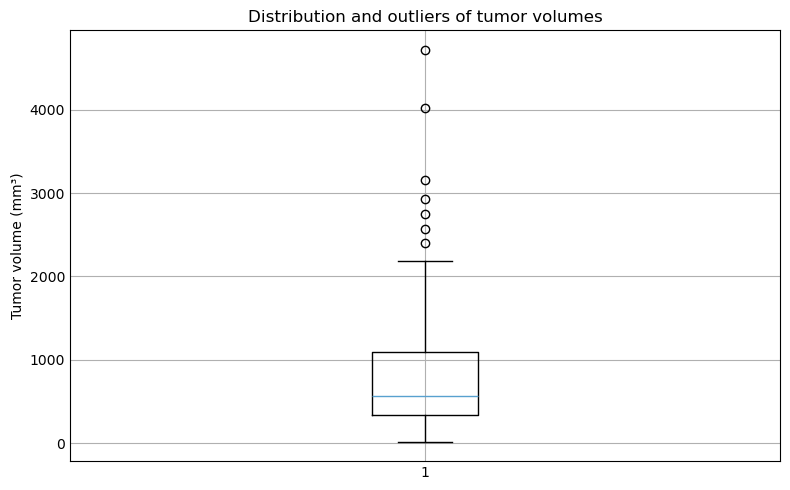

In [51]:
plt.figure(figsize=(8, 5))

plt.boxplot(data["Volume [mm³]"])

plt.ylabel("Tumor volume (mm³)")
plt.title("Distribution and outliers of tumor volumes")

plt.tight_layout()
plt.show()

Conclusion: The median tumor volume is approximately 550 mm³, meaning that half of the measurements are below this value and half are above it. The middle 50% of tumor volumes range from approximately 330 to 1,100 mm³. The distribution is positively skewed, as several unusually large tumor volumes appear above the upper whisker. These outliers reach values of over 4,000 mm³, indicating considerable variation in tumor size.

***
## Applying Tumor Growth Models

In this section, four different tumor growth models are applied to the dataset. These models describe tumor growth in different ways and allow us to compare their ability to represent the observed tumor volume over time.

***
## Parameters optimaliseren

***
## Resultaten visualiseren

***
## Conclusie